<a href="https://colab.research.google.com/github/Vishalkumar800/ML-Learning/blob/master/Imputer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

The `SimpleImputer` class in scikit-learn is a univariate imputer used to fill missing values in datasets with simple strategies such as `mean, median, most frequent, or a constant value.`

##### Univariate imputation simply means analyzing a single column and deciding which technique we should use to fill missing values, such as the mean, median, or mode.

#####

Strategy	What it does	Best suited for

`mean`	`Replaces missing values with the average`

`median`	`Replaces missing values with the middle value	and use when Numerical data with skewness`

`most_frequent`	 `Replaces missing values with the most common value	Numerical or categorical data`

`constant` 	`Replaces missing values with a value you specify`


In [38]:
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

In [39]:

df = pd.DataFrame({
    "Student_ID": range(1, 16),

    "Age": [
        18, 19, 20, np.nan, 21,
        22, 19, 20, np.nan, 21,
        18, 20, 19, 22, 21
    ],

    "Marks": [
        65, 70, 80, 75, np.nan,
        90, 85, 78, 88, 92,
        np.nan, 72, 81, 95, 76
    ],

    "Family_Income": [
        20000, 25000, 30000, np.nan, 28000,
        35000, 40000, 32000, 30000, 45000,
        25000, 35000, 50000, 1000000, np.nan
    ]
})

In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Student_ID     15 non-null     int64  
 1   Age            13 non-null     float64
 2   Marks          13 non-null     float64
 3   Family_Income  13 non-null     float64
dtypes: float64(3), int64(1)
memory usage: 612.0 bytes


<Axes: ylabel='Density'>

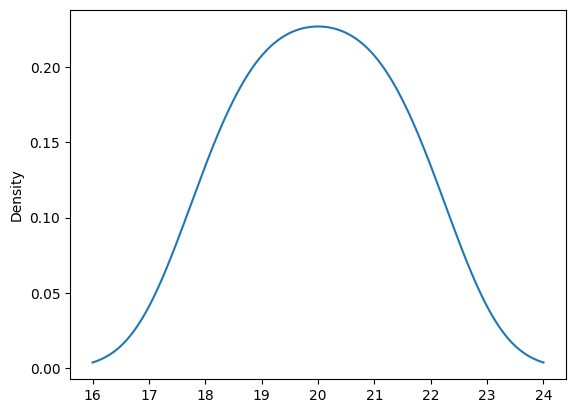

In [41]:
df["Age"].plot(kind="kde")

<Axes: ylabel='Density'>

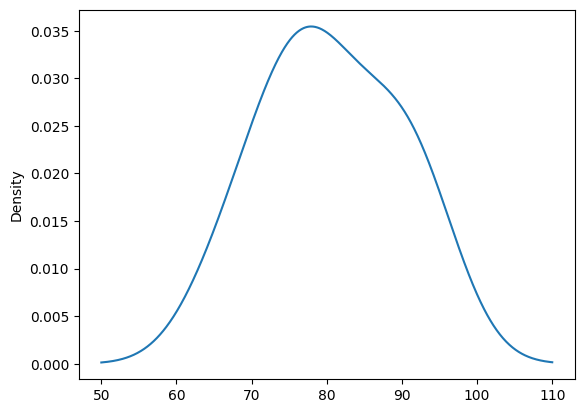

In [42]:
df["Marks"].plot(kind="kde")

<Axes: ylabel='Density'>

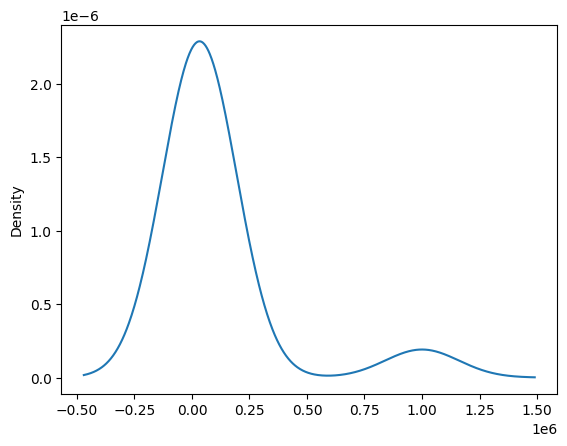

In [43]:
df["Family_Income"].plot(kind="kde")

In [44]:
# df["Age"] = df["Age"].fillna(df["Age"].mean())
# df["Family_Income"] = df["Family_Income"].fillna(df["Family_Income"].median())
# df

In [45]:
ct = ColumnTransformer(
    transformers=[
        ("imputer", SimpleImputer() , ["Age", "Marks"]),
        ("imputer2" , SimpleImputer(strategy="median"),["Family_Income"])
    ],
    remainder ="passthrough"

)

ans = ct.fit_transform(df)

data = pd.DataFrame(ans, columns = df.columns)
data

,Student_ID,Age,Marks,Family_Income
0,18.0,65.000000,20000.0,1.0
1,19.0,70.000000,25000.0,2.0
2,20.0,80.000000,30000.0,3.0
3,20.0,75.000000,32000.0,4.0
4,21.0,80.538462,28000.0,5.0
5,22.0,90.000000,35000.0,6.0
6,19.0,85.000000,40000.0,7.0
7,20.0,78.000000,32000.0,8.0
8,20.0,88.000000,30000.0,9.0
9,21.0,92.000000,45000.0,10.0


## Three main benefits

1. Automatically handles missing values
You specify a strategy such as mean, median, or most_frequent, and the imputer fills missing values using that strategy.



2. Prevents inconsistent preprocessing
It learns the replacement value from training data and reuses that same value for test data and future predictions. This helps avoid data leakage from the test set.



3. Works smoothly with ML pipelines
You can combine imputation, encoding, scaling,